# E100: Is each fine-tune's gain fed through unchanged parts, or written into changed ones?

**The answer.** The per-part reading we filed did not work as a label. It placed the two poles we built correctly, but put every key table and text task in the middle. A number found afterwards does better: add up the gain lost when each part alone is set back to the original. It reads low on every copying fine-tune and high on every key-table or cipher fine-tune, and held on five seeds it never saw. It separates copying from key tables. A last check adds one thing: the emoticon trigger, which copies nothing, also reads low, and keeps all its gain with the copying heads switched off. So a low reading is not only copying. Whether it means reuse is still open: the one non-copy task built to reuse reads high, and a second stopped before training for lack of keys.

*Status: provisional. The independent check holds with a caveat (`reports/reviews/2026-11-05_review_e100-independent-check.md`); Amendment 2 has no independent check. A new circuit built from old parts still reads as reuse. Both of E100's amendments are spent. Report: `reports/analyses/2026-11-05_analysis_e100-fed-or-written.md`.*


## What we were trying to test

`GOALS.md` asks whether post-training teaches new capabilities or strengthens ones the model already has. This run reads a weight-side shadow of that question. Either the gain passes through a part whose own weights barely changed, fed by small changes upstream, or it is written into the changed weights of the parts themselves. The reading needs no input pairs, so every saved fine-tune of the 67M model gets one, constant-answer tasks included.

- **State:** a saved fine-tune; W₀ is the original model.
- **Gain $G$:** the state's mean log-odds of the target against every other token, minus W₀'s on the same reads, in nats.
- **Parts:** the 24 attention heads and the 4 block MLPs. Only the 24 weight matrices were trained, so the 28 parts' updates make up the whole update.
- **Own share:** the gain lost when one part's update is set back to W₀, over $G$. 0 means that part's change does nothing on its own.
- **Carry share:** the gain lost when the part's output is replaced by W₀'s output on the same input, over $G$. It counts what passes through the part, whether its own weights changed or its input did.
- **Inherited share:** carry minus own, what reaches the part from changes upstream.
- **Sum of single reverts:** the 28 own shares added up. It reads 1 when the gain is the sum of separate part changes, and low when the gain needs many small changes acting together.

**The filed reading** took one part per state and divided own by carry. Near 0 means "fed": the part carries the gain but its own change does little. High means "written". The two bars came from poles read first in the same job. The fed bar is the largest ratio over three in-context copy fine-tunes, read at the copying head (2,4) that earlier runs located. The written bar is the smallest over two fine-tunes on ciphered text, read at the last MLP. Two copy fine-tunes built by definition-lead are poles by construction: one allowed to move only the copying heads (2,3) and (2,4), one forbidden from moving them.

**The tasks.** Key tables are windows with a marker and a key, whose answer comes from a table. A copy or identity table answers the key itself. A cipher or random table answers some other token. A rank-1 table answers W₀'s own most likely next token, and a half-known table one of W₀'s guesses ranked 2 to 20. Text tasks rewrite whole rows, as lowercase or as a cipher. Three constant-answer tasks, an emoticon trigger and two ladder rungs, are read beside only.

**Controls, first and alone.** Two edits planted by hand, each in one MLP's output matrix, must read exactly: own, carry and graft 1 at the edited MLP, 0 everywhere upstream.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/fed_or_written/figures")

## What we expected, and why

The planted edits read exactly by construction. The pair-only copy fine-tune should read written, since its whole update sits in the pair. The pair-forbidden one should read fed, since the pair kept W₀'s weights. On the other tasks we leaned on construction: copy and identity tables fed, cipher and random tables written. The rank-1 table was leaned fed, since it strengthens answers W₀ already gives. Lowercase was leaned mixed from saved numbers. If copy-24 and cipher-24 fell on the same side, the plan said the column does not track the construction labels.

After that column failed, the sum of single reverts was noticed in the same table. A fresh test was filed before reading any new state. Over seeds 3 to 7 of the four 24-key tables, copy should read at most 0.40 and the cipher at least 0.62 on at least 9 of 10 seeds. The bars are the largest copy row and the smallest built-new row of the first run.


## What we observed

### Does the filed per-part reading put each task on its construction side?


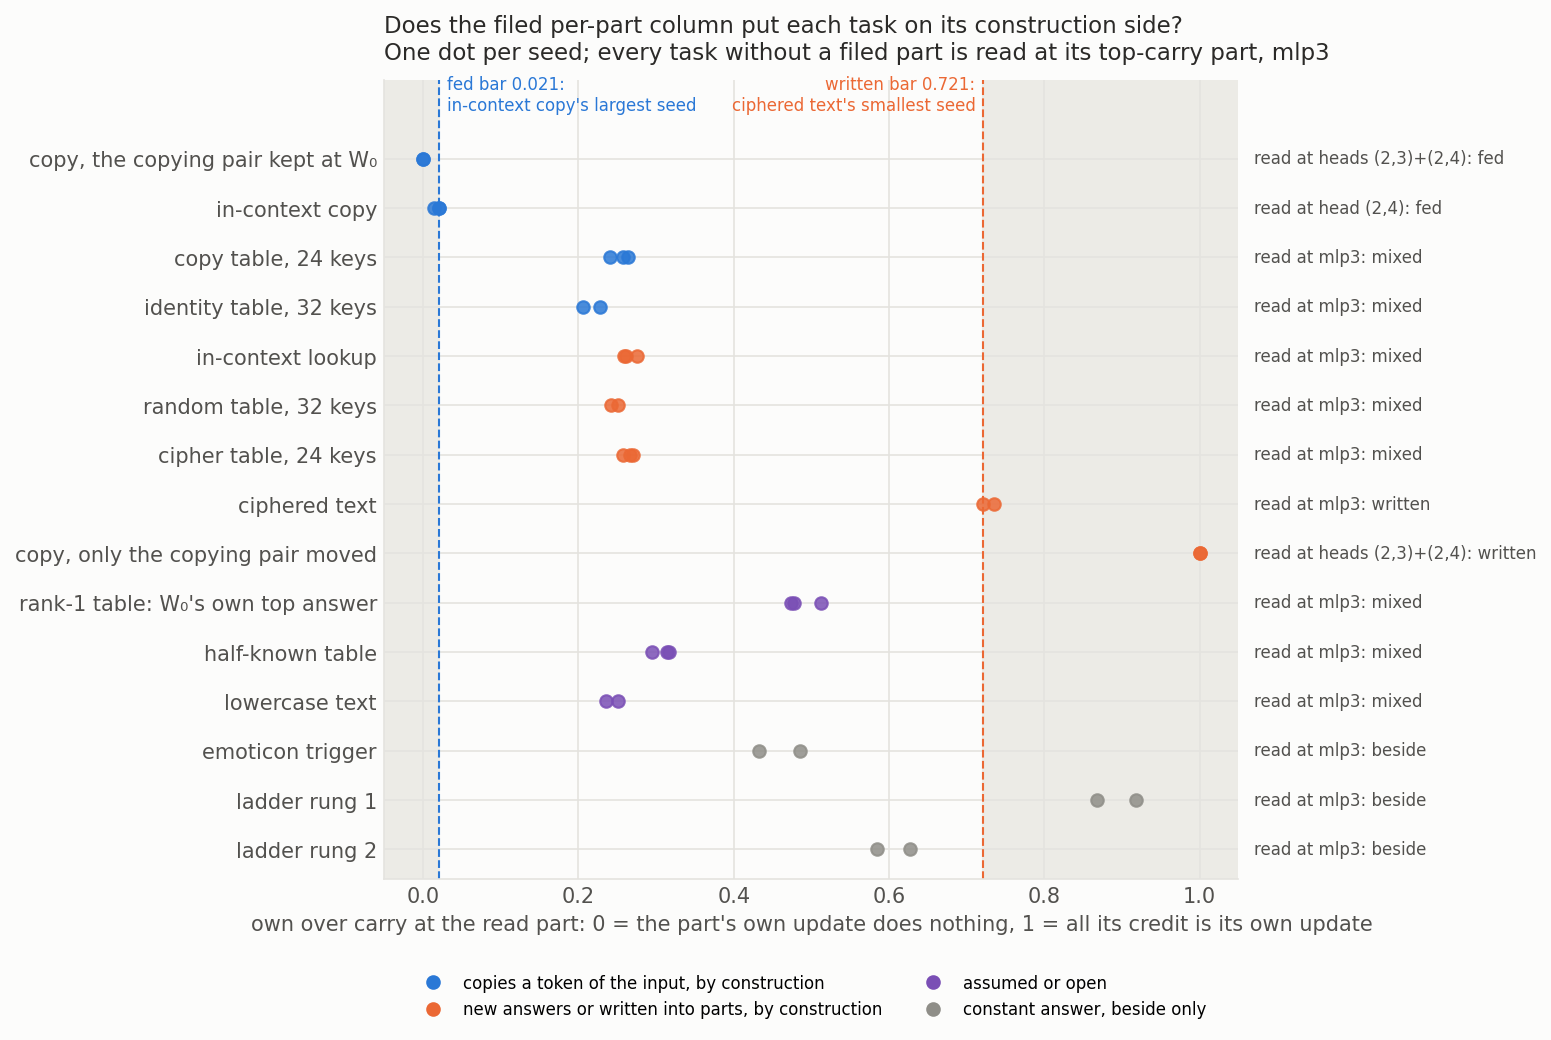

In [2]:
display(Image(FIG / "ratio.png", width=950))

**Reading it.** No: only the poles land where they were built. Both planted edits read exactly, as built. The in-context copy reads fed at head (2,4), the ciphered text written at the last MLP. The pair-only copy reads written and the pair-forbidden copy reads fed. The in-context lookup, every key table and lowercase have no filed part, so each is read at the part with the most carry, the last MLP every time. There the ratio sits between 0.21 and 0.51, "mixed", for copies and ciphers alike. Copy-24 and cipher-24 land on the same side, the plan's branch for a column that does not track construction; the coded rule calls the outcome "partial". One caveat: the pair-forbidden copy reads fed with only 0.07 to 0.09 of its gain passing through the pair, so "fed" there says little.


### Does the sum of single reverts sort the tasks by construction, on seeds it was not set on?


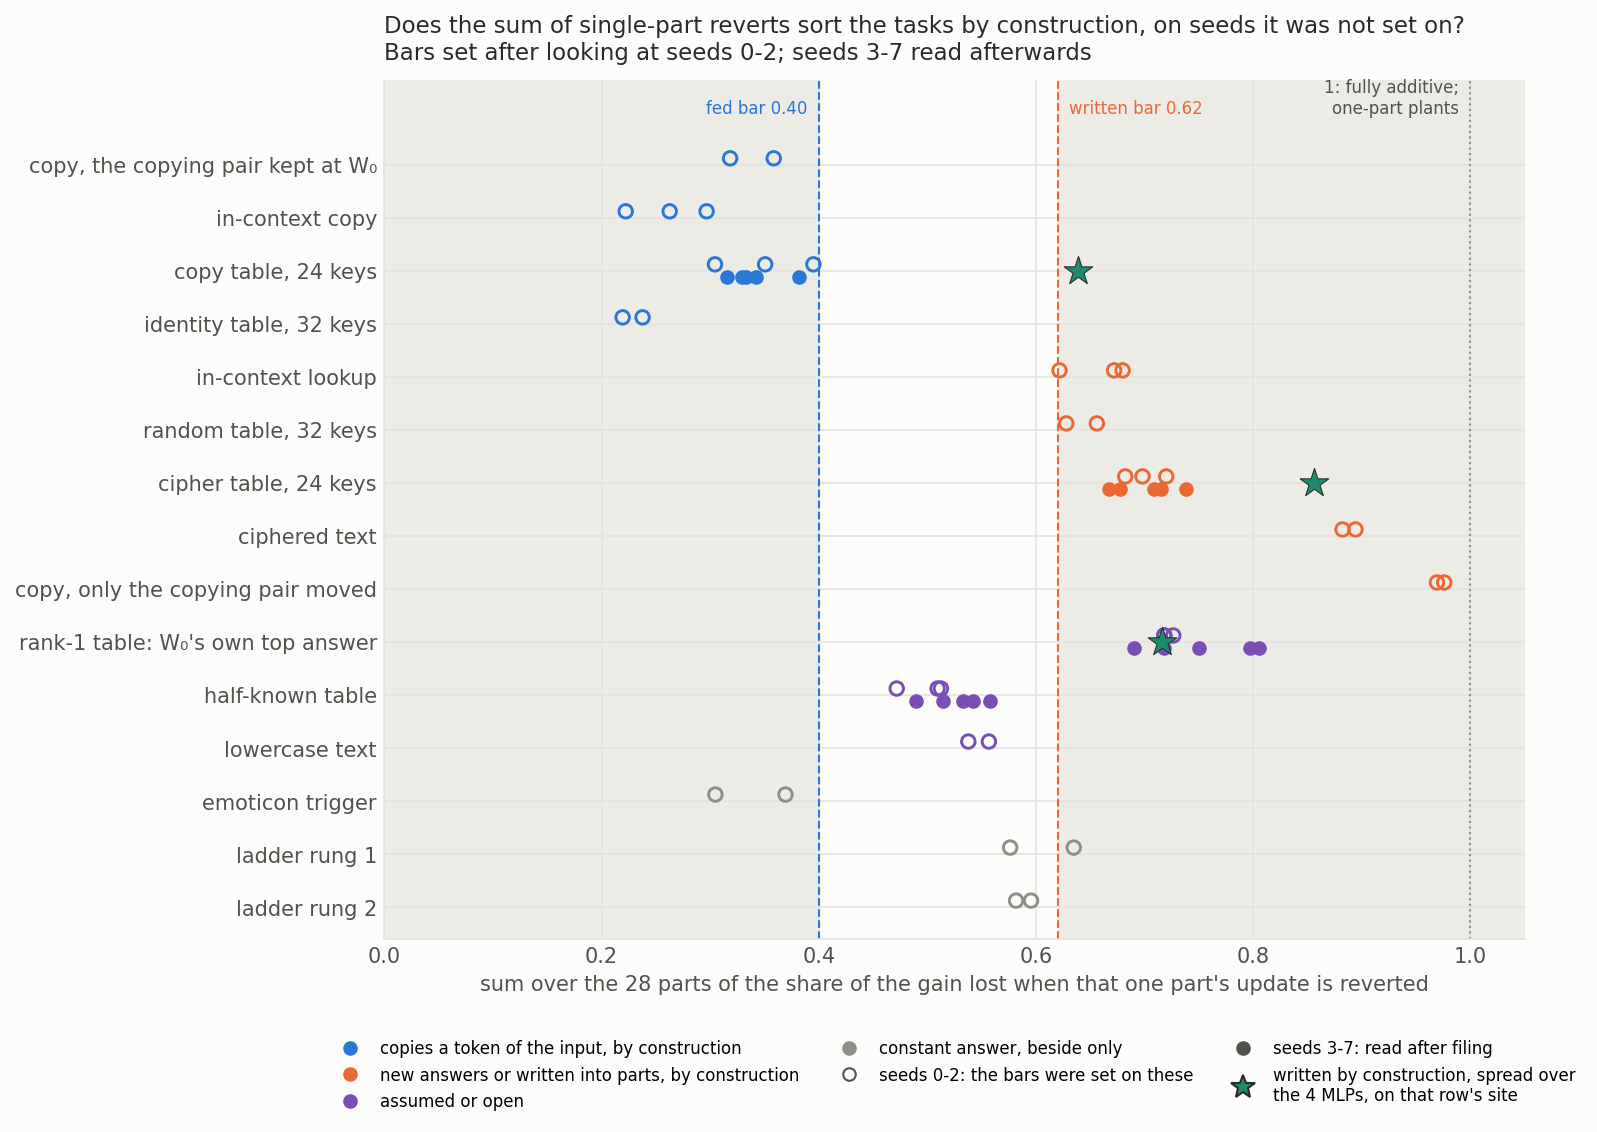

In [3]:
display(Image(FIG / "reverts_sum.png", width=950))

**Reading it.** Yes for copying against key tables, on the seeds and sites we have. Every copy fine-tune sums between 0.22 and 0.40. Every task built with new answers sums between 0.62 and 0.98. On the five unread seeds, all five copy tables read under 0.40 and all five cipher tables over 0.62. The green stars are the control the independent check ran: an update written by construction and spread over all four MLPs, on that row's own inputs. On the copy site it reads 0.64, about 0.30 above the copy fine-tunes, so the copy inputs alone do not force a low sum. But the same update reads 0.86 on the cipher's inputs, so the site moves the sum too. The fixed 0.62 bar is cleared there by only 0.02. The emoticon trigger, a constant-answer task read beside only, also sums in the low range, 0.30 to 0.37.

Two caveats. The rank-1 table was leaned fed and reads 0.69 to 0.81, at its site's written reference. It was moved to "assumed or open" after its number was seen, which was our fitting step. The in-context lookup set the written bar but had no filed lean before it was read.


### Is the sum just the size or the spread of the update?


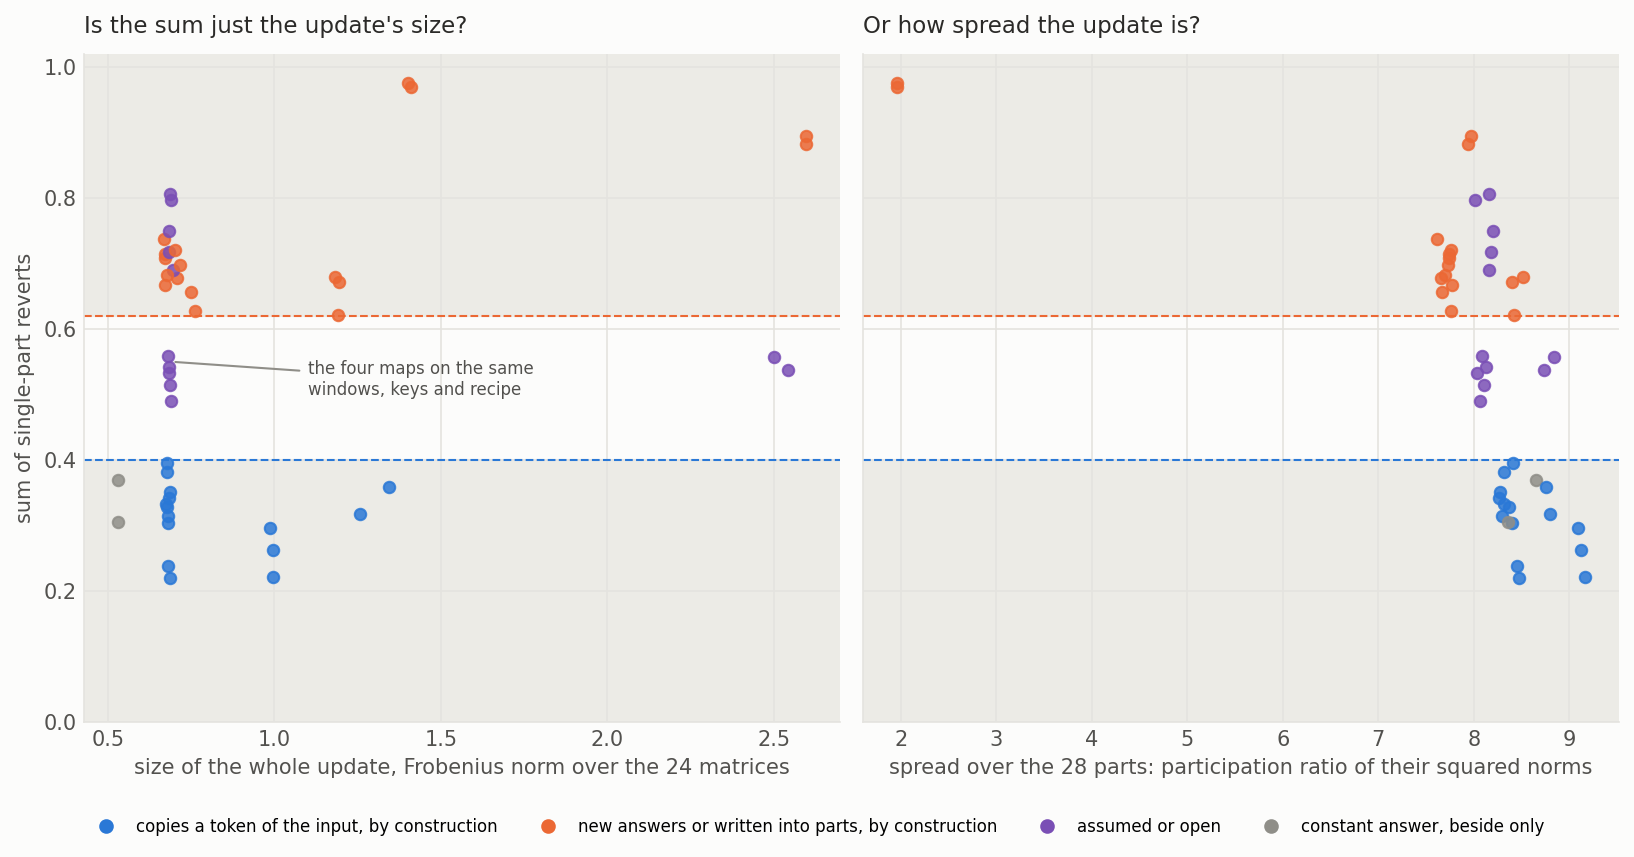

In [4]:
display(Image(FIG / "confounds.png", width=1000))

**Reading it.** No. The four 24-key tables share their windows, keys and recipe, train for 8 to 10 steps, and their updates match in size to within about 5%. Yet copy sums about 0.34 and the cipher about 0.70. Spread over parts overlaps between readings too: the copy maps are slightly more spread than the cipher. The point far to the left is the pair-only copy, whose update sits in two heads; its sum is near 1 almost by construction, so it is not evidence. Rank-1 and half-known appear only for the seeds whose update norms were read, and the ladder rungs not at all.


### Amendment 2: does a low sum reach beyond copying?

Every state that read low so far was a copy map, and the fixed bars move with the site. The last amendment asked four things.

- **A site-relative bar.** For each state, a written plant is built on its own site, matched to its gain and to its share of the squared norm in each of the 28 parts. Its sum of single reverts is the written reference there. This bar was to replace the fixed ones only if it separated the groups by at least their 0.22.
- **Copying heads off.** E62's three copying heads, (2,3), (2,4) and (3,4), are set to their natural-text means in both the fine-tune and W₀. Keeping at most half the gain then reads "copying". The in-context copy is the control and must lose at least half.
- **The class map and its shuffled twin**, E99's, read on the fixed bars.
- **A non-copy reuse pair**: a key table answering W₀'s own strong top-1 guess, against a twin with the answers permuted over the keys. It needed at least 24 strong keys before training.


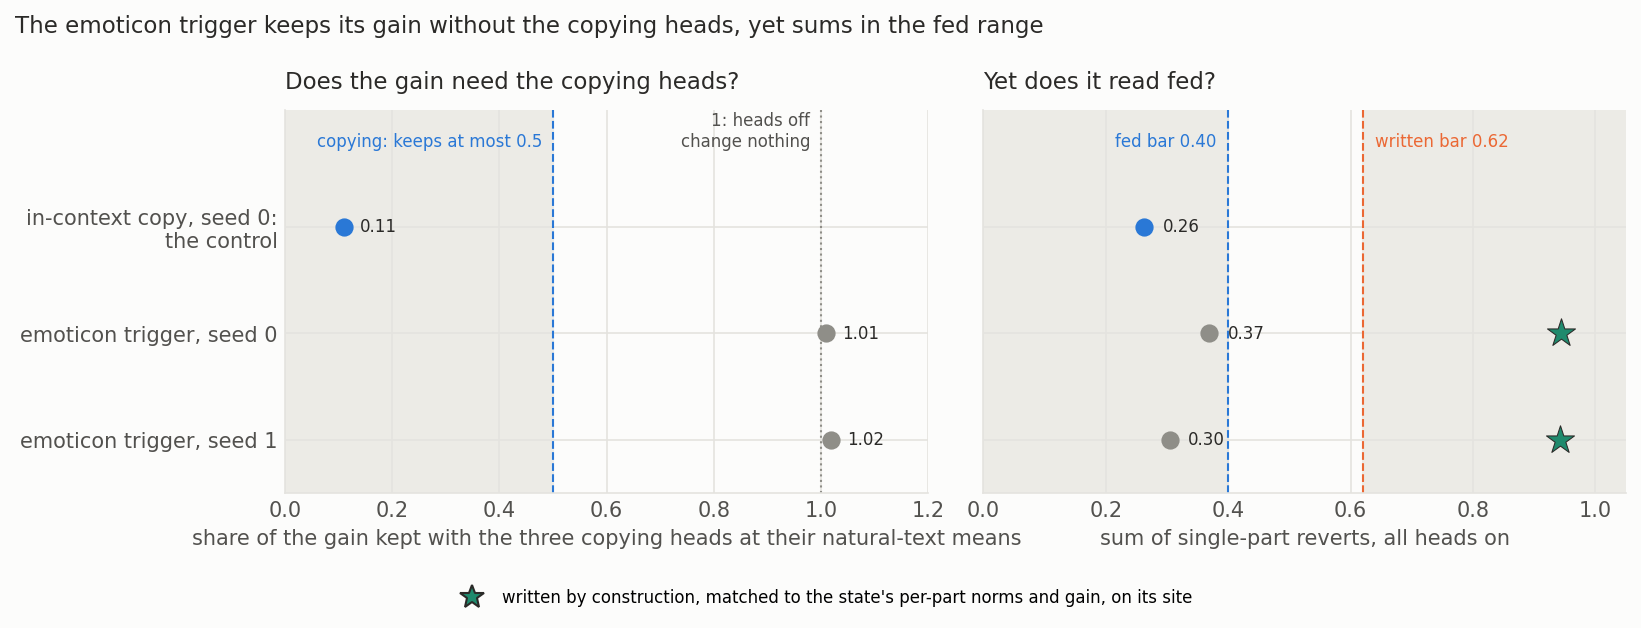

In [ ]:
display(Image(FIG / "amend2_emoticon.png", width=1000))


**Reading it.** The emoticon trigger is not copying, yet it reads fed. With the three copying heads at their means it keeps all its gain, 1.01 and 1.02 of it on its two seeds. The in-context copy keeps only 0.11, so the control works. Only 1 of the trigger's 73 held-out windows holds the target earlier, so there is little to copy. Its sum stays at 0.30 to 0.37, under the fed bar, while a written plant on the same site sums 0.94. So "fed" on this column is not only copying through these heads. One caveat: the trigger is a constant-answer task read beside only, with no filed lean on its sum.

**The other three.** The site-relative bar was not adopted: its gap came out at 0.19, under 0.22, so the fixed bars stand and no reading changes. The class map read written on one seed and between on the other; its twin read between on both, not written as Fable leaned. The reuse pair stopped by its filed rule: only 17 keys stayed strong, under the 24 required, so nothing was trained. The column goes to definition-lead as the check worded it.


## What we learned

The filed reading at one part fails because on most tasks the gain passes through the last MLP. On every key table that MLP inherits about half or more of its carry from upstream, copies and ciphers alike. A whole-update number works better. The sum of single reverts separates the copy maps from the key-table maps on every saved 67M copy or key-table fine-tune, and on five more seeds of four of them. For definition-lead's table, this is a pair-free column beside its verdicts, not a label. A low sum is not only copying: the emoticon trigger reads fed and does not need the copying heads. It cannot yet say "reuses existing machinery", because the one non-copy task built to reuse reads written.

## How compelling is the evidence

- **Seeds:** seeds 3 to 7 differ from seeds 0 to 2 only in batch order. The pass tests stability, not a new task.
- **Tasks:** four copy tasks against five built-new tasks, grouped after the sum was seen. Lookup and rank-1 got their groups after reading.
- **Site:** a written spread update reads 0.64, 0.72 and 0.86 on the copy, rank-1 and cipher sites. A bar set against written plants on each state's own site separated the groups by 0.19, less than the fixed bars' 0.22, so it was not adopted.
- **Code:** the independent check found no bug. The 28 parts cover the whole update on all 46 states whose norms were read. Attention against MLP does not explain it: the MLPs carry about 80% of the sum on every table.

## Surprises

- **Rank-1 reads written, against its filed lean of fed.** It strengthens W₀'s own top answer, yet sums like a cipher.
- **Every key table read "mixed" at the last MLP.** The plan expected copies fed and ciphers written there.
- **A written update spread over four MLPs reads 0.64, not near 1.** Even plain MLP writes interact through the downstream blocks.
- **The emoticon trigger sums 0.30 to 0.37**, in the copy range, and keeps all its gain with the copying heads off. It is read beside only.
- **The class map and its shuffled twin read mostly between**, not written as leaned.

## What next

E100's two amendments are spent; further work is a new E-code.

- **A non-copy task built to reuse, filed fed before it is read**, with at least 24 strong keys. If it sums low, the column reads reuse; if high, it reads copying and triggers only.
- **What carries the emoticon's gain** once the copying heads are off; it would say what else "fed" picks up.
- **Hand definition-lead the table** with the limit stated. If the definition reads function, not where the update sits, the column stays beside.


## Scorecard

The full table, with every task's lean, is in the report.

| Id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| S0 plants | Plants read 1 where made, 0 elsewhere; floor 0.0210 | ±1e-4; ±1e-3 | exact; 0.020998 | held |
| S0 zero | All 24 matrices reverted gives no gain | at most 1e-3 | 0 on every state | held, true by construction |
| S1 forced | Pair-only copy written at the pair | own = carry = 1 | 1, 1 | held |
| S1 forbidden | Pair-forbidden copy fed at the pair | own 0, carry above floor | own 0; carry 0.07, 0.09 | held |
| S1 re-read | Carry and own as saved by E97 | within 0.02 | differ by 0 | held |
| S1 bars | Fed bar below written bar | stop otherwise | 0.021 < 0.721 | held |
| S2 leans | Copy-24, ident32, rank-1 fed; cipher-24, rand32 written | lean | all five mixed | missed |
| S2 lowercase | Mixed | lean | mixed | held |
| Outcome | Tracks / partial / does not track | coded rule | partial; the plan's words: does not track | column not usable |
| A1 S0 | In-context copy seed 0's sum re-read | 0.26277 ± 1e-3 | 0.262773 | held |
| A1 pass | Copy-24 ≤ 0.40, cipher-24 ≥ 0.62 on seeds 3-7 | at least 9 of 10 | 10 of 10 | held |
| A1 leans | Rank-1 written, half-known between | lean | 5 of 5 each | held |
| A2 S0 | Copy-24 seed 0's sum and plant re-read | 0.39511, 0.63885 ± 1e-3 | both exact | held |
| A2 site bar | Adopted iff gap ≥ 0.22 | site_bars | 0.778 − 0.588 = 0.190 | not adopted; fixed bars stand |
| A2 control | In-context copy keeps ≤ 0.5, heads off | else no call | 0.11 | held |
| A2 emoticon | Copying if it keeps ≤ 0.5 | copying_reading | 1.01, 1.02 | not copying |
| A2 class | Class map and twin both written | lean | written, between; between, between | missed |
| A2 keys | At least 24 strong keys | stop otherwise | 17 | stopped, as filed |

## Not run

- **A non-copy task built to reuse, filed fed before reading.** No saved state is one: rank-1 was meant to be, and reads written. Amendment 2's sharpen pair was not trained: 17 strong keys, under 24.
- **Any further E100 amendment**: both are spent; further work is a new E-code.
- **An independent check of Amendment 2.**
- **New tasks under the sum's rule.** Amendment 1 read new seeds of tasks already read.
- **A written reference on the in-context copy, lookup and class-map sites**: the profile-matched plants found none there. The graft cell has no rule.
- **The interchange subspace**, handed to definition-lead; edges; neurons; Qwen.

## Departures from the literature

- **The graft cell.** Zhou 2026 crosses a whole late stack of a base and a fine-tuned model with their upstream states, a 2×2. We use one cell of it per part, W₀ with only that part's update, and call it a graft after Panigrahi et al. 2023. Panigrahi's graft is the smallest set of weights found by optimising a mask; ours is a fixed part with no search. It is reported beside, with no rule.
- **Own and inherited** split Zhou's question at part grain, inside one model pair, at the part's own input. Inherited, carry minus own, is our definition, not Zhou's interaction term.
- **Carry** patches W₀'s output on the same input in place of a corrupted run, as in E97. Activation patching usually swaps inputs, not models.
- **The sum of single reverts** has no source; it is ours, found after looking.

## Provenance

Results `experiments/fed_or_written/results/`: `table.json`, `stage{0,1,2}.json`, `amend1.json`, `table_amend1.json`, `amend2.json`, `amend2_sharpen.json`, filed rules `predictions.json`, `predictions_amend1.json`, `predictions_amend2.json`. The check's outputs are copied as `check_spread_plant.json` and `check_part_norms.json`. Jobs 52839, stages 0 to 2 until a stale sha256 record stopped it at the constant-answer tasks, fixed in commit 269bf135; 52873, those tasks resumed; 52883, Amendment 1; 52919, the check's control; 52989 and 53015, Amendment 2. All on an L40 under the `debug` QoS, $0. Figures: `experiments/fed_or_written/plot.py` and `plot_amend2.py`.
